# 00 - Análisis exploratorio de datos

Taiwanese Bankruptcy Prediction Dataset (UCI #572). Antes de ejecutar: `uv run python scripts/download_data.py`.

## Carga inicial

In [1]:
from pathlib import Path

import pandas as pd

from inf396.data import TARGET, load_dataset

df = load_dataset()
df.shape

(6819, 96)

In [2]:
df.head()

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490


## Variable objetivo

In [3]:
counts = df[TARGET].value_counts()
pd.DataFrame({'n': counts, 'proporción': counts / len(df)})

,n,proporción
Bankrupt?,,
0,6599,0.967737
1,220,0.032263


## Tipos de datos y valores faltantes

In [4]:
print(df.dtypes.value_counts())
print('Valores faltantes totales:', df.isna().sum().sum())

float64    93
int64       3
Name: count, dtype: int64
Valores faltantes totales: 0


## Configuración de análisis

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_auc_score

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
INK, MUTED = "#1f2937", "#9ca3af"
ACCENT = "#2563eb"

X = df.drop(columns=TARGET)
y = df[TARGET]
FIG_DIR = Path("../results/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

## Variables constantes, binarias y duplicados

In [6]:
nunique = X.nunique()
print("Constantes:", nunique[nunique <= 1].index.tolist())
print("Binarias:", nunique[nunique == 2].index.tolist())
print("Filas duplicadas:", df.duplicated().sum())

Constantes: ['Net Income Flag']
Binarias: ['Liability-Assets Flag']
Filas duplicadas: 0


## Escala y asimetría

Varias razones están acotadas en [0, 1], pero otras toman valores del orden de $10^9$. Se revisa cuántas variables salen de [0, 1] y cuáles son más asimétricas.

In [7]:
out_of_unit = X.max()[X.max() > 1].sort_values()
print(f"{len(out_of_unit)} variables con máximo > 1")
display(out_of_unit.to_frame("max").tail(10))
skew = X.skew().abs().sort_values(ascending=False)
display(skew.head(10).round(1).to_frame("|asimetría|"))

24 variables con máximo > 1


,max
Inventory/Current Liability,9.910000e+09
Total debt/Total net worth,9.940000e+09
Research and development expense rate,9.980000e+09
Inventory Turnover Rate (times),9.990000e+09
Operating Expense Rate,9.990000e+09
Total Asset Growth Rate,9.990000e+09
Fixed Assets Turnover Frequency,9.990000e+09
Current Asset Turnover Rate,1.000000e+10
Cash Turnover Rate,1.000000e+10
Quick Asset Turnover Rate,1.000000e+10


,|asimetría|
Fixed Assets to Assets,82.6
Current Ratio,82.6
Total income/Total expense,82.3
Net Value Growth Rate,80.3
Contingent liabilities/Net worth,79.7
Realized Sales Gross Profit Growth Rate,77.9
Operating Profit Growth Rate,71.7
Operating Profit Rate,70.2
Continuous Net Profit Growth Rate,67.1
Total Asset Return Growth Rate Ratio,62.5


## Colinealidad

Pares con |r| > 0.95: 23 | > 0.99: 12


|r|
Current Liabilities/Equity          Current Liability to Equity       1.0000
Current Liabilities/Liability       Current Liability to Liability    1.0000
Debt ratio %                        Net worth/Assets                  1.0000
Operating Gross Margin              Gross Profit to Sales             1.0000
Net Value Per Share (A)             Net Value Per Share (C)           0.9998
Operating Gross Margin              Realized Sales Gross Margin       0.9995
Realized Sales Gross Margin         Gross Profit to Sales             0.9995
Net Value Per Share (B)             Net Value Per Share (A)           0.9993
                                    Net Value Per Share (C)           0.9992
Operating Profit Per Share (Yuan ¥) Operating profit/Paid-in capital  0.9987

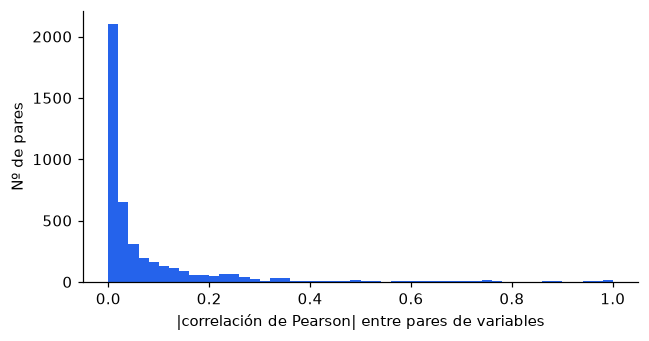

In [8]:
corr = X.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().sort_values(ascending=False)
print("Pares con |r| > 0.95:", (pairs > 0.95).sum(), "| > 0.99:", (pairs > 0.99).sum())
display(pairs.head(10).round(4).to_frame("|r|"))

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(pairs.values, bins=50, color=ACCENT)
ax.set_xlabel("|correlación de Pearson| entre pares de variables")
ax.set_ylabel("Nº de pares")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_corr_hist.png")
plt.show()

## Poder discriminante univariado

AUC-ROC de cada razón financiera por separado, orientado para que sea ≥ 0,5 (si el AUC original es < 0,5 se invierte el signo de la variable). Es solo una referencia exploratoria: no se usa para seleccionar variables sobre todo el dataset.

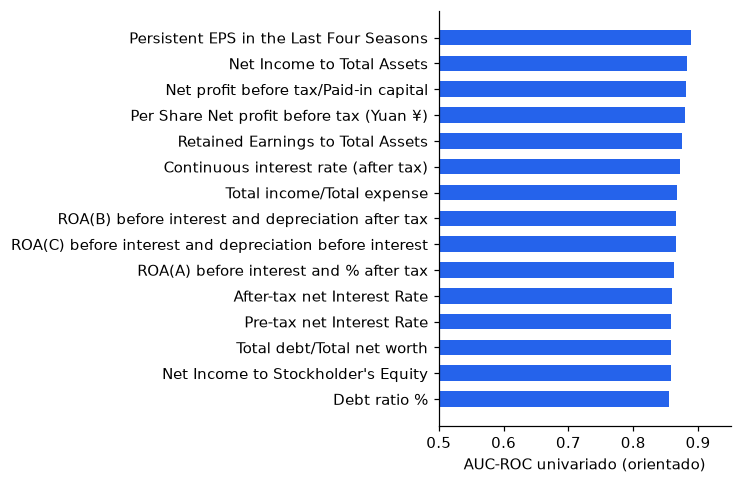

Variables con AUC > 0.8: 30 de 95


In [9]:
auc_raw = X.apply(lambda s: roc_auc_score(y, s))
auc = np.maximum(auc_raw, 1 - auc_raw).sort_values(ascending=False)
top = auc.head(15)[::-1]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top.index, top.values, color=ACCENT, height=0.6)
ax.set_xlim(0.5, 0.95)
ax.set_xlabel("AUC-ROC univariado (orientado)")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_auc_univariado.png")
plt.show()
print("Variables con AUC > 0.8:", (auc > 0.8).sum(), "de", len(auc))

## Distribuciones por clase

Se comparan las tres variables más discriminantes entre empresas sanas y en quiebra, en escala de rangos para evitar el efecto de los valores extremos.

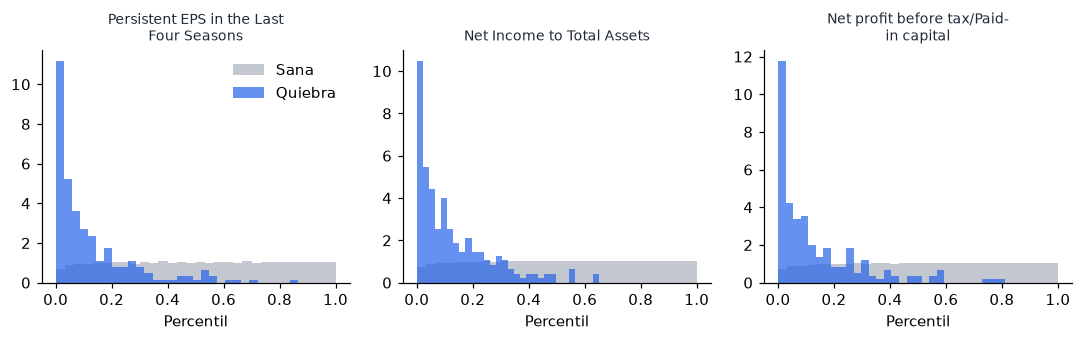

In [10]:
import textwrap

best = auc.index[:3]
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, col in zip(axes, best):
    ranks = X[col].rank(pct=True)
    ax.hist(ranks[y == 0], bins=30, density=True, alpha=0.6, color=MUTED, label="Sana")
    ax.hist(ranks[y == 1], bins=30, density=True, alpha=0.7, color=ACCENT, label="Quiebra")
    ax.set_title(textwrap.fill(col, 28), fontsize=9, color=INK)
    ax.set_xlabel("Percentil")
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_distribuciones_clase.png")
plt.show()

## Observaciones preliminares

- **Variables inútiles:** `Net Income Flag` es constante y se puede eliminar. `Liability-Assets Flag` es binaria.
- **Duplicados y faltantes:** no hay filas duplicadas ni valores faltantes.
- **Escala:** 24 variables superan 1, algunas del orden de $10^9$, y las asimetrías llegan a ~80. Los modelos sensibles a la escala (SVM, redes) necesitarán transformación; los basados en árboles no.
- **Colinealidad:** 23 pares con |r| > 0,95 (12 con |r| > 0,99). Es relevante para modelos lineales y para interpretar importancias.
- **Señal:** 30 de las 95 variables tienen AUC univariado > 0,8; las más discriminantes son de rentabilidad (EPS, ROA, utilidad sobre activos). Las empresas en quiebra se concentran en los percentiles bajos de estas variables.
- **Pendiente:** outliers, estabilidad de la señal y decisiones de preprocesamiento definitivas, que irán en `src/inf396/preprocessing.py`.